# 06 — 3GPP TR 38.811 non-terrestrial channels

**Purpose.** Build an ECEF satellite-to-ground topology, sample an NTN-TDL
realization, inspect geometry and loss components, compare synchronized and
absolute-delay OFDM timing, and round-trip the complete realization.

The orbit helper is intentionally simple and the packaged tables remain
`pending_independent_review`; production orbit and weather providers should remain
authoritative.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython import get_ipython

get_ipython().run_line_magic("matplotlib", "inline")


def find_repo_root(start: Path | None = None) -> Path:
    start = Path.cwd() if start is None else start
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "configs").is_dir():
            return candidate
    raise RuntimeError("Run this notebook from a Channel Dataset repository checkout")


def as_numpy(value):
    if isinstance(value, torch.Tensor):
        return value.detach().cpu().numpy()
    return np.asarray(value)


ROOT = find_repo_root()
SOURCE_DIRECTORY = str(ROOT / "src")
if SOURCE_DIRECTORY not in sys.path:
    sys.path.insert(0, SOURCE_DIRECTORY)

from channel_dataset.core import ExecutionContext

execution = ExecutionContext("torch", "double", "cpu")
backend = execution.array_backend
print(f"Repository: {ROOT.name} | backend={execution.backend} | precision={execution.precision}")

Repository: Channel_Dataset | backend=torch | precision=double


## 1. Construct a simple NGSO-to-ground topology

In [2]:
from channel_dataset.channels.wireless import NTNTopologyBatch
from channel_dataset.channels.wireless.tr38811 import EARTH_RADIUS_M, circular_equatorial_orbit
from channel_dataset.core import RealizationMetadata

SAMPLES = 16
SAMPLE_RATE_HZ = 15_360_000.0
platform_position, platform_velocity = circular_equatorial_orbit(
    600_000.0, 0.0, SAMPLES, SAMPLE_RATE_HZ, execution
)
tx_position = platform_position[None, None, :, :]
tx_velocity = platform_velocity[None, None, :, :]
rx_position = backend.array([[[[EARTH_RADIUS_M, 0.0, 0.0]]]], dtype="float64")
zeros_tx = backend.zeros(tuple(tx_position.shape), dtype="float64")
zeros_rx = backend.zeros(tuple(rx_position.shape), dtype="float64")
topology_metadata = RealizationMetadata(
    "wireless", "tr38811_topology", 1, "torch", "double", "cpu",
    "deterministic", "0" * 64, {}, "0.1.0", standard_version="15.4.0",
)
topology = NTNTopologyBatch(
    tx_position, rx_position, tx_velocity, zeros_rx, zeros_tx, zeros_rx,
    "satellite", "ground", backend.zeros((1, 1), dtype="bool"), topology_metadata,
)
print("topology:", topology.shape, "trajectory samples:", topology.trajectory_length)

topology: (1, 1, 1) trajectory samples: 16


## 2. Sample the packaged NGSO NTN-TDL model

In [3]:
from channel_dataset.channels.wireless import (
    ChannelSamplingRequest,
    NTNChannelSamplingRequest,
    register_tr38811_models,
)
from channel_dataset.config import load_config
from channel_dataset.registry import ModelRegistry

envelope = load_config(ROOT / "configs/wireless/tr38811/ngso_s_tdl.yaml")
registry = ModelRegistry()
register_tr38811_models(registry)
model = registry.create(envelope)


def make_request():
    sampling = ChannelSamplingRequest(
        1, SAMPLES, SAMPLE_RATE_HZ, execution, execution.random_stream(6601), "ntn-ngso"
    )
    return NTNChannelSamplingRequest(sampling, topology)


realization = model.realize(make_request())
replay = model.realize(make_request())
assert torch.equal(realization.cir.coefficients, replay.cir.coefficients)
assert torch.all(realization.geometry.slant_range_m >= EARTH_RADIUS_M * 0.0)
assert torch.isfinite(realization.large_scale.total_db).all()

print("CIR:", realization.cir.shape)
print("initial range (km):", round(float(realization.geometry.slant_range_m[0, 0, 0, 0]) / 1e3, 3))
print("initial delay (ms):", round(float(realization.geometry.propagation_delay_s[0, 0, 0, 0]) * 1e3, 6))
print("LOS:", bool(realization.los_mask[0, 0, 0]))

CIR: (1, 1, 1, 1, 1, 3, 16)
initial range (km): 600.0
initial delay (ms): 2.001385
LOS: False


## 3. Inspect geometry and decomposed attenuation

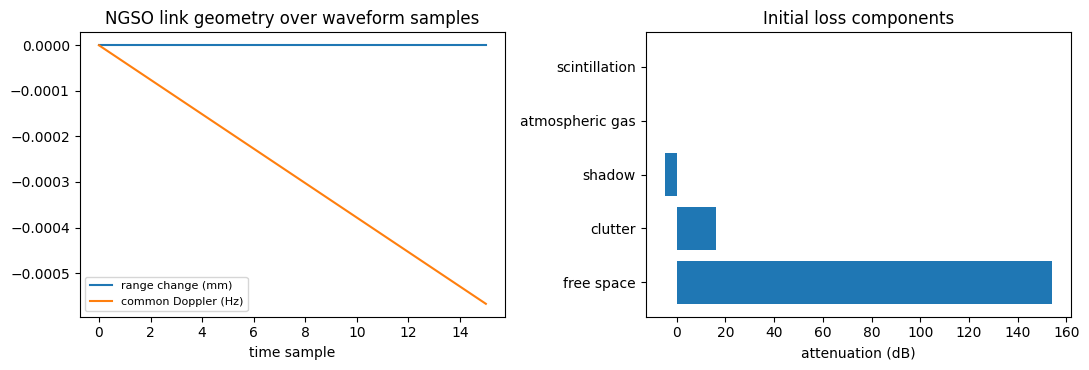

total initial attenuation (dB): 165.466


In [4]:
geometry = realization.geometry
loss = realization.large_scale
components = {
    "free space": loss.free_space_db,
    "clutter": loss.clutter_db,
    "shadow": loss.shadow_fading_db,
    "atmospheric gas": loss.atmospheric_gas_db,
    "scintillation": loss.scintillation_db,
}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(as_numpy(geometry.slant_range_m[0, 0, 0] - geometry.slant_range_m[0, 0, 0, 0]) * 1e3, label="range change (mm)")
axes[0].plot(as_numpy(geometry.common_doppler_hz[0, 0, 0]), label="common Doppler (Hz)")
axes[0].set(title="NGSO link geometry over waveform samples", xlabel="time sample")
axes[0].legend(fontsize=8)
labels = list(components)
values = [float(value[0, 0, 0, 0]) for value in components.values()]
axes[1].barh(labels, values)
axes[1].set(title="Initial loss components", xlabel="attenuation (dB)")
fig.tight_layout()
plt.show()
component_sum = sum(value for name, value in components.items()) + loss.building_entry_db + loss.rain_db + loss.cloud_db
assert torch.allclose(component_sum, loss.total_db)
print("total initial attenuation (dB):", round(float(loss.total_db[0, 0, 0, 0]), 3))

## 4. Compare synchronized and absolute-delay OFDM

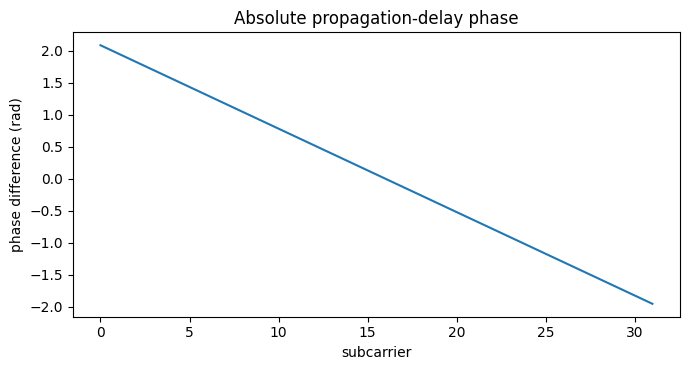

maximum magnitude change: 1.6543612251060553e-24


In [5]:
from channel_dataset.channels.wireless import ntn_to_ofdm
from channel_dataset.channels.wireless.transforms import subcarrier_frequencies

frequencies = subcarrier_frequencies(32, 15_000.0, execution)
synchronized = ntn_to_ofdm(realization, frequencies, include_propagation_delay=False)
absolute = ntn_to_ofdm(realization, frequencies, include_propagation_delay=True)
magnitude_error = torch.max(torch.abs(torch.abs(synchronized.coefficients) - torch.abs(absolute.coefficients)))
assert float(magnitude_error) < 1e-10
assert torch.isfinite(absolute.coefficients).all()

phase_difference = torch.angle(absolute.coefficients / synchronized.coefficients)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(as_numpy(phase_difference[0, 0, 0, 0, 0, 0]))
ax.set(title="Absolute propagation-delay phase", xlabel="subcarrier", ylabel="phase difference (rad)")
fig.tight_layout()
plt.show()
print("maximum magnitude change:", float(magnitude_error))

## 5. Persist the complete NTN realization

In [6]:
from tempfile import TemporaryDirectory

from channel_dataset.channels.wireless import load_ntn_realization, save_ntn_realization

with TemporaryDirectory() as temporary_directory:
    path = save_ntn_realization(Path(temporary_directory) / "ntn", realization)
    loaded = load_ntn_realization(path, execution)
assert torch.equal(loaded.cir.coefficients, realization.cir.coefficients)
assert torch.equal(loaded.geometry.slant_range_m, realization.geometry.slant_range_m)
print("complete NTN persistence round-trip: exact")

complete NTN persistence round-trip: exact


## Manual check and next experiments

- Change altitude, initial phase, or ground location and inspect visibility/elevation.
- Compare NTN-TDL and antenna-aware NTN-CDL profiles.
- Supply site-specific atmospheric inputs rather than treating this example as a weather engine.
- Use an external orbit propagator by passing its ECEF state vectors directly.